# 00 · Prerequisites Bootcamp: Excel → Python for demand planners

**Business question:** *Can I do in Python everything I already do in Excel with demand data, and then more?*

This notebook teaches only what the project needs, using the **real Intel microprocessor data** we'll analyse later. Every step shows the Excel equivalent.

**How to use a notebook**
- Click a grey code cell and press **Shift + Enter** to run it. The result appears below.
- Run cells **top to bottom**. If things get weird, use *Restart* → *Run All*.
- Top-right kernel should say **Semiconductor DP (.venv)**.

**Sections:** 1. Python basics · 2. Load data · 3. Filter & sort · 4. Formula columns · 5. PivotTables & SUMIFS · 6. XLOOKUP · 7. Moving averages & time shifts · 8. Charts · 9. Back to Excel · 10. Git basics · 11. Exercises

## 1. Python basics (just enough)
A **variable** is like a named cell. A **list** is a column of values. A **dict** is a little lookup table (key → value). A **function** is a reusable formula you write once.

In [1]:
lead_time_weeks = 4                      # a variable (like cell B1 = 4)
weekly_orders = [520, 480, 610, 550]     # a list (like a column A1:A4)
asp_by_group = {1: "High", 2: "Mid", 3: "Low"}   # a dict (like a 2-column lookup table)

def average(values):
    """Like =AVERAGE(A1:A4)"""
    return sum(values) / len(values)

avg = average(weekly_orders)
print(f"Average weekly orders: {avg:.0f} units")          # f-string = text with values inserted
print(f"Demand over the lead time: {avg * lead_time_weeks:.0f} units")
print("ASP group 2 means:", asp_by_group[2])

for week, qty in enumerate(weekly_orders, start=1):      # a loop = 'for each row'
    flag = "HIGH" if qty > avg else "normal"             # like =IF(A1>avg,"HIGH","normal")
    print(f"Week {week}: {qty} -> {flag}")

Average weekly orders: 540 units
Demand over the lead time: 2160 units
ASP group 2 means: Mid
Week 1: 520 -> normal
Week 2: 480 -> normal
Week 3: 610 -> HIGH
Week 4: 550 -> HIGH


## 2. Load the data (= File → Open)
`pandas` is Python's spreadsheet engine. A **DataFrame** (`df`) is a sheet: rows and named columns.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path.cwd().parent / "data" / "raw" / "intel_msom_2022.csv"   # notebooks/ is one level down
df = pd.read_csv(DATA)

print("Rows x columns:", df.shape)
df.head()          # first 5 rows, like scrolling to the top of the sheet

Rows x columns: (26114, 8)


,Distribution Center,Product Offering,Generation,SKU,ASP Group,Week,Forecasted Demand,Customer Orders
0,ALPHA,A,2,SKU-A-2,1,1,8949,11146
1,ALPHA,B,2,SKU-B-2,1,1,11146,3503
2,ALPHA,C,1,SKU-C-1,3,1,1274,5892
3,ALPHA,C,2,SKU-C-2,4,1,20717,3185
4,ALPHA,F,1,SKU-F-1,6,1,24522,6529


In [3]:
df.info()          # column names + data types (like checking cell formats)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26114 entries, 0 to 26113
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Distribution Center  26114 non-null  object
 1   Product Offering     26114 non-null  object
 2   Generation           26114 non-null  int64 
 3   SKU                  26114 non-null  object
 4   ASP Group            26114 non-null  int64 
 5   Week                 26114 non-null  int64 
 6   Forecasted Demand    26114 non-null  int64 
 7   Customer Orders      26114 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 1.6+ MB


In [4]:
df.describe().round(1)   # quick stats per numeric column: count, mean, std, min, quartiles, max

,Generation,ASP Group,Week,Forecasted Demand,Customer Orders
count,26114.0,26114.0,26114.0,26114.0,26114.0
mean,3.2,10.7,98.1,39023.1,12324.7
std,0.9,5.2,51.0,82622.9,21509.1
min,1.0,1.0,1.0,0.0,16.0
25%,2.0,7.0,57.0,1592.0,1035.0
50%,3.0,12.0,98.0,9076.0,4299.0
75%,4.0,14.0,139.8,35649.0,14013.0
max,5.0,22.0,187.0,1150510.0,381369.0


**Reading the columns**
- `Distribution Center`: one of Intel's 5 warehouses (Greek-letter names).
- `Product Offering`: product line letter.
- `Generation`: product generation (newer = higher).
- `SKU`: product line + generation, e.g. `SKU-A-2`.
- `ASP Group`: average selling price category.
- `Week`: 1 … 187 (relative weeks, not calendar dates).
- `Forecasted Demand`: Intel's forecast for that week.
- `Customer Orders`: what customers actually ordered.

## 3. Filter & sort (= AutoFilter and Sort)

In [5]:
# Excel: AutoFilter SKU = 'SKU-A-2' AND DC = 'ALPHA', then sort by Week
one = df[(df["SKU"] == "SKU-A-2") & (df["Distribution Center"] == "ALPHA")].sort_values("Week")
print(len(one), "weeks of data for SKU-A-2 at ALPHA")
one.head(8)

89 weeks of data for SKU-A-2 at ALPHA


,Distribution Center,Product Offering,Generation,SKU,ASP Group,Week,Forecasted Demand,Customer Orders
0,ALPHA,A,2,SKU-A-2,1,1,8949,11146
97,ALPHA,A,2,SKU-A-2,1,2,11338,19427
195,ALPHA,A,2,SKU-A-2,1,3,14538,13854
280,ALPHA,A,2,SKU-A-2,1,4,18694,12261
364,ALPHA,A,2,SKU-A-2,1,5,7325,11306
459,ALPHA,A,2,SKU-A-2,1,6,7166,3025
552,ALPHA,A,2,SKU-A-2,1,7,7166,8917
634,ALPHA,A,2,SKU-A-2,1,8,8439,5096


In [6]:
# Unique values (= the filter drop-down list)
print("DCs:", sorted(df["Distribution Center"].unique()))
print("Number of SKUs:", df["SKU"].nunique())
print("Generations:", sorted(df["Generation"].unique()))

DCs: ['ALPHA', 'BETA', 'DELTA', 'EPSILON', 'GAMMA']
Number of SKUs: 86
Generations: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 4. Formula columns (= typing a formula in a new column and filling down)
In pandas, one line applies the formula to **every row at once**. No fill-down needed.

In [7]:
df["Error"] = df["Forecasted Demand"] - df["Customer Orders"]     # + means over-forecast
df["Abs Error"] = df["Error"].abs()                                # =ABS(...)
df[["SKU", "Week", "Forecasted Demand", "Customer Orders", "Error", "Abs Error"]].head()

,SKU,Week,Forecasted Demand,Customer Orders,Error,Abs Error
0,SKU-A-2,1,8949,11146,-2197,2197
1,SKU-B-2,1,11146,3503,7643,7643
2,SKU-C-1,1,1274,5892,-4618,4618
3,SKU-C-2,1,20717,3185,17532,17532
4,SKU-F-1,1,24522,6529,17993,17993


In [8]:
# The project's main KPI, WMAPE = SUMPRODUCT(ABS(F-A)) / SUM(A)
wmape = df["Abs Error"].sum() / df["Customer Orders"].sum()
bias_pct = df["Error"].sum() / df["Customer Orders"].sum()
print(f"Intel forecast, all data: WMAPE = {wmape:.1%}  ->  accuracy = {1 - wmape:.1%},  bias = {bias_pct:+.1%}")
print("(A first peek only. Day 2 does this properly, by lag, SKU and DC, with significance tests.)")

Intel forecast, all data: WMAPE = 238.6%  ->  accuracy = -138.6%,  bias = +216.6%
(A first peek only. Day 2 does this properly, by lag, SKU and DC, with significance tests.)


**🔎 Wait, a negative accuracy?** When WMAPE is above 100%, `1 − WMAPE` goes below zero. That happens when the forecast is *far* off.

A raw bias this large is a **red flag to investigate, not a conclusion**. A good planner first asks *"am I comparing like with like?"*:
- Is `Forecasted Demand` a forecast for that single week, or a cumulative / multi-week figure?
- Was it made 1 week ahead, or many weeks ahead?
- Do the two columns share the same units?

Day 1 (data understanding) answers these questions from the dataset paper before we score Intel's forecast properly on Day 2. This is a real lesson: **never report a KPI until you're sure what the columns mean.**

## 5. PivotTables & SUMIFS (= `groupby` and `pivot_table`)

In [9]:
# SUMIFS-style subtotal: total orders per DC
df.groupby("Distribution Center")["Customer Orders"].sum().sort_values(ascending=False)

Distribution Center
EPSILON    145440034
GAMMA       74889495
DELTA       70092309
ALPHA       29923552
BETA         1502405
Name: Customer Orders, dtype: int64

In [10]:
# A real PivotTable: rows = Generation, columns = DC, values = sum of orders
pd.pivot_table(df, index="Generation", columns="Distribution Center",
               values="Customer Orders", aggfunc="sum", margins=True, margins_name="Total")

Distribution Center,ALPHA,BETA,DELTA,EPSILON,GAMMA,Total
Generation,,,,,,
1,664641.0,NaN,356852.0,1162729.0,63296.0,2247518
2,10030518.0,292784.0,20245103.0,38412730.0,10244162.0,79225297
3,10599349.0,519487.0,17595708.0,42402470.0,28926144.0,100043158
4,8209158.0,670559.0,28799325.0,57235998.0,30507022.0,125422062
5,419886.0,19575.0,3095321.0,6226107.0,5148871.0,14909760
Total,29923552.0,1502405.0,70092309.0,145440034.0,74889495.0,321847795


In [11]:
# Several KPIs per group at once (like a PivotTable with multiple value fields)
by_dc = df.groupby("Distribution Center").agg(
    orders=("Customer Orders", "sum"),
    forecast=("Forecasted Demand", "sum"),
    abs_error=("Abs Error", "sum"),
)
by_dc["wmape"] = by_dc["abs_error"] / by_dc["orders"]
by_dc["bias_%"] = (by_dc["forecast"] - by_dc["orders"]) / by_dc["orders"]
by_dc.style.format({"orders": "{:,.0f}", "forecast": "{:,.0f}", "abs_error": "{:,.0f}",
                    "wmape": "{:.1%}", "bias_%": "{:+.1%}"})

,orders,forecast,abs_error,wmape,bias_%
Distribution Center,,,,,
ALPHA,"29,923,552","33,831,160","21,694,930",72.5%,+13.1%
BETA,"1,502,405","1,589,137","1,322,896",88.1%,+5.8%
DELTA,"70,092,309","175,072,519","111,172,600",158.6%,+149.8%
EPSILON,"145,440,034","690,026,765","556,087,791",382.3%,+374.4%
GAMMA,"74,889,495","118,530,946","77,700,135",103.8%,+58.3%


## 6. XLOOKUP (= `merge`)
Bring information from another table into this one by matching a key.

In [12]:
# A small lookup table: ASP group -> label (in real life this might be a product master sheet)
asp_lookup = pd.DataFrame({"ASP Group": sorted(df["ASP Group"].unique())})
asp_lookup["Price Tier"] = ["Tier " + str(g) for g in asp_lookup["ASP Group"]]

df = df.merge(asp_lookup, on="ASP Group", how="left")   # = XLOOKUP(ASP Group, lookup[ASP Group], lookup[Price Tier])
df[["SKU", "ASP Group", "Price Tier"]].drop_duplicates().head()

,SKU,ASP Group,Price Tier
0,SKU-A-2,1,Tier 1
1,SKU-B-2,1,Tier 1
2,SKU-C-1,3,Tier 3
3,SKU-C-2,4,Tier 4
4,SKU-F-1,6,Tier 6


## 7. Moving averages & time shifts (= helper columns referencing rows above)
- `.shift(1)` = "the value one row above" (last week).
- `.rolling(4).mean()` = a 4-week moving average.

⚠️ We use `.shift(1)` **before** rolling, so the average uses only *past* weeks. Including the current week would be **data leakage**: using the answer to predict the answer.

In [13]:
one = one.copy()
one["Last Week"] = one["Customer Orders"].shift(1)
one["MA4 (past 4 wks)"] = one["Customer Orders"].shift(1).rolling(4).mean()   # a simple moving-average forecast
one[["Week", "Customer Orders", "Last Week", "MA4 (past 4 wks)", "Forecasted Demand"]].head(8)

,Week,Customer Orders,Last Week,MA4 (past 4 wks),Forecasted Demand
0,1,11146,NaN,NaN,8949
97,2,19427,11146.0,NaN,11338
195,3,13854,19427.0,NaN,14538
280,4,12261,13854.0,NaN,18694
364,5,11306,12261.0,14172.00,7325
459,6,3025,11306.0,14212.00,7166
552,7,8917,3025.0,10111.50,7166
634,8,5096,8917.0,8877.25,8439


In [14]:
# Which forecast was better for this SKU-DC: Intel's, or a simple 4-week moving average?
valid = one.dropna(subset=["MA4 (past 4 wks)"])
for name, col in [("Intel forecast", "Forecasted Demand"), ("4-week moving average", "MA4 (past 4 wks)")]:
    w = (valid[col] - valid["Customer Orders"]).abs().sum() / valid["Customer Orders"].sum()
    print(f"{name:<24} WMAPE = {w:.1%}")
print("\nThis is a tiny preview of 'Forecast Value Add' - comparing forecasts fairly on the same weeks.")

Intel forecast           WMAPE = 68.4%
4-week moving average    WMAPE = 97.8%

This is a tiny preview of 'Forecast Value Add' - comparing forecasts fairly on the same weeks.


## 8. Charts (= Insert → Line chart)

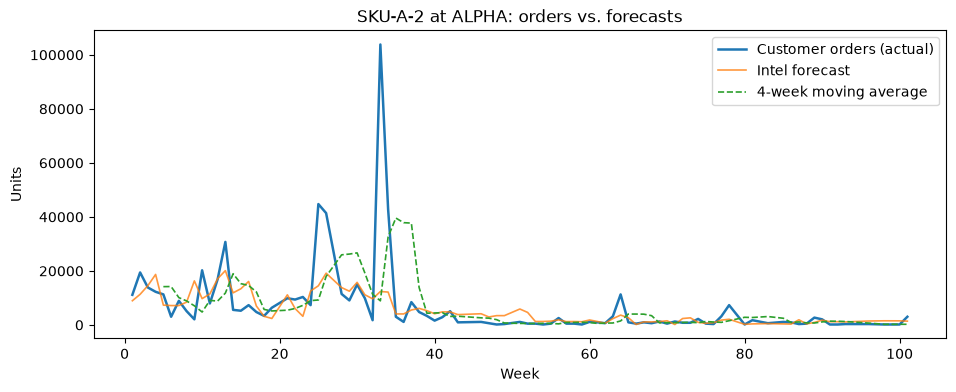

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(one["Week"], one["Customer Orders"], label="Customer orders (actual)", linewidth=1.8)
ax.plot(one["Week"], one["Forecasted Demand"], label="Intel forecast", linewidth=1.2, alpha=0.8)
ax.plot(one["Week"], one["MA4 (past 4 wks)"], label="4-week moving average", linewidth=1.2, linestyle="--")
ax.set(title="SKU-A-2 at ALPHA: orders vs. forecasts", xlabel="Week", ylabel="Units")
ax.legend()
plt.show()

## 9. Back to Excel (= Save As .xlsx)
Planners and managers live in Excel. A Python model is only useful if its results reach them.

In [16]:
OUT = Path.cwd().parent / "data" / "processed" / "bootcamp_dc_summary.xlsx"
by_dc.to_excel(OUT, sheet_name="DC summary")
print("Saved:", OUT)

Saved: C:\Users\dheer\Desktop\PROJECTS\Demand Forecasting & Inventory Optimization using Machine Learning\data\processed\bootcamp_dc_summary.xlsx


## 10. Git basics: how your work gets saved to GitHub
Think of Git as **"Track Changes + Version History" for a whole folder**, and GitHub as the cloud copy.

| Step | Command (PowerShell terminal in VS Code) | Meaning |
|---|---|---|
| 1 | `git status` | What changed since the last save point? |
| 2 | `git add notebooks/00_prerequisites_bootcamp.ipynb` | Put this file in the "ready to save" box (`git add -A` = everything) |
| 3 | `git commit -m "Complete bootcamp exercises"` | Create a save point with a message |
| 4 | `git push` | Upload save points to GitHub |
| 5 | `git log --oneline` | List of save points (your project's history) |

A good commit message says **what** changed, in the imperative mood: *"Add bias significance tests"*, not *"stuff"*.

In this project `/checkpoint` does steps 1–4 for you at the end of each phase. You'll still do it once by hand after the exercises below, so you know what's happening.

## 11. Exercises (5)
Try each one in the empty cell, **then** reveal the solution cell below it (click the "…" / expand arrow).

**Exercise 1.** How many rows belong to the `GAMMA` distribution center? *(Hint: filter, then `len()`.)*

In [17]:
# your answer here

GAMMA_len = len(df[df["Distribution Center"] == "GAMMA"])
print(f"Number of rows for Distribution Center GAMMA are {GAMMA_len}")

Number of rows for Distribution Center GAMMA are 6054


In [18]:
print(len(df[df["Distribution Center"] == "GAMMA"]))

6054


**Exercise 2.** Which **SKU** has the highest total customer orders across all DCs and weeks? *(Hint: `groupby` + `sum` + `idxmax()`.)*

In [19]:
# your answer here
total_orders = df.groupby("SKU")["Customer Orders"].sum()
print("SKU by highest total customer orders is: ", total_orders.idxmax(), f"{total_orders.max():,.0f} units")

SKU by highest total customer orders is:  SKU-C-4 23,352,836 units


In [20]:
totals = df.groupby("SKU")["Customer Orders"].sum()
print(totals.idxmax(), f"{totals.max():,.0f} units")

SKU-C-4 23,352,836 units


**Exercise 3.** Build a pivot table: rows = `Generation`, values = WMAPE of Intel's forecast. Which generation is hardest to forecast?

In [21]:
# your answer here

gen = df.groupby("Generation")[["Abs Error", "Customer Orders"]].sum()
gen["WMAPE"] = gen["Abs Error"] / gen["Customer Orders"]
print(gen["WMAPE"].map("{:.1%}".format))
print("Generation hardest to forecast:", gen["WMAPE"].idxmax())

Generation
1    236.2%
2    289.4%
3    248.4%
4    213.6%
5    114.2%
Name: WMAPE, dtype: object
Generation hardest to forecast: 2


In [22]:
g = df.groupby("Generation")[["Abs Error", "Customer Orders"]].sum()
g["WMAPE"] = g["Abs Error"] / g["Customer Orders"]
print(g["WMAPE"].map("{:.1%}".format))
print("Hardest:", g["WMAPE"].idxmax())

Generation
1    236.2%
2    289.4%
3    248.4%
4    213.6%
5    114.2%
Name: WMAPE, dtype: object
Hardest: 2


**Exercise 4.** For SKU-A-2 at ALPHA, add a column `MA8` = 8-week moving average of *past* orders. Is its WMAPE better or worse than MA4?

In [23]:
# your answer here

one["MA8 (past 8 wks)"] = one["Customer Orders"].shift(1).rolling(8).mean()
m = one.dropna(subset=["MA8 (past 8 wks)"])
for col in ["MA4 (past 4 wks)", "MA8 (past 8 wks)"]:
    print(col, f"{(m[col] - m['Customer Orders']).abs().sum() / m['Customer Orders'].sum():.1%}")
print("Longer windows are closer, but will tend to react slower than shorter windows to the trends shown in the recent past.")

MA4 (past 4 wks) 99.5%
MA8 (past 8 wks) 99.2%
Longer windows are closer, but will tend to react slower than shorter windows to the trends shown in the recent past.


In [24]:
one["MA8"] = one["Customer Orders"].shift(1).rolling(8).mean()
v = one.dropna(subset=["MA8"])
for col in ["MA4 (past 4 wks)", "MA8"]:
    print(col, f"{(v[col] - v['Customer Orders']).abs().sum() / v['Customer Orders'].sum():.1%}")
print("Longer windows are smoother but react more slowly to trends.")

MA4 (past 4 wks) 99.5%
MA8 99.2%
Longer windows are smoother but react more slowly to trends.


**Exercise 5.** Count how many SKU-DC combinations exist, and how many weeks each has on average. *(Hint: `groupby([...]).size()`.)* Why might some have fewer than 187 weeks?

In [25]:
# your answer here

sizes = df.groupby(["SKU","Distribution Center"]).size()
print("Total number of SKU-DC combinations are:", len(sizes), "\nAverage number of weeks each combination has are:", round(sizes.mean(), 1), "weeks")
print("Combinations which have fewer than 187 weeks -> \n1. The product is launched after week 1. or \n2. Had reached end-of-life before week 187.")


Total number of SKU-DC combinations are:

 394 
Average number of weeks each combination has are: 66.3 weeks
Combinations which have fewer than 187 weeks -> 
1. The product is launched after week 1. or 
2. Had reached end-of-life before week 187.


In [26]:
sizes = df.groupby(["SKU", "Distribution Center"]).size()
print(len(sizes), "SKU-DC combinations; average", round(sizes.mean(), 1), "weeks each")
print("Fewer than 187 weeks -> the product launched after week 1 or reached end-of-life before week 187 (life cycles!).")

394

 SKU-DC combinations; average 66.3 weeks each
Fewer than 187 weeks -> the product launched after week 1 or reached end-of-life before week 187 (life cycles!).


---
## What a demand planner takes away
- Everything you do in Excel (filter, formulas, pivots, lookups, charts) is a line or two of pandas. It is repeatable, and it works on millions of rows.
- The project's core KPIs (WMAPE, bias) are just formula columns plus a `groupby`.
- **Using only past data** (`.shift(1)`) is the habit that separates real forecasting from fake accuracy.
- Results go back to Excel in one line, so you can always hand them to Excel-based teams.

**Checkpoint questions**
1. What is the pandas equivalent of a PivotTable, and of XLOOKUP?
2. Why do we write `.shift(1).rolling(4).mean()` instead of `.rolling(4).mean()` for a forecast?
3. In one sentence, what's the difference between `git commit` and `git push`?

# Answer for the checkpoint questions:

1. Equivalent for PivotTable is .pivot_table() and for XLOOKUP is .merge()
2. Seperates the Real forecasting from the fake analysis. Will also account for Forecast Value Add (FVA).
3. commit saves the progree with a message and push will upload the changes to the GitHub.